# TP04: Advanced Visualization, Comparative Analysis, and Interactivity

**Module:** Data Visualization  
**Academic Year:** 2026/2027

## 1. Introduction

This practical work explores global development indicators using statistical visualization, correlation analysis, interactive visualization, geographical mapping, and network analysis.

The dataset covers 217 economies from 2000 to 2023.


## 2. Libraries and Project Modules

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_preprocessing import load_data, clean_data
from src.visualizations import (
    prepare_visualization_data,
    plot_scatter,
    plot_bubble,
    plot_density,
    plot_correlation_heatmap
)
from src.interactive_visualizations import (
    create_gdp_time_series,
    create_life_expectancy_map
)
from src.network_analysis import (
    build_regional_graph,
    draw_regional_graph
)

sns.set_theme(style="whitegrid")


## 3. Data Loading and Preprocessing

In [2]:
df = load_data()

print("Original dataset shape:", df.shape)
display(df.head())


Original dataset shape: (5208, 9)


,ISO3,Country,Region,Income_Group,Year,GDP_Per_Capita,Life_Expectancy,Internet_Users_Pct,Population
0,ABW,Aruba,Latin America & Caribbean,High income,2000,20681.023027,72.939,15.442823,90588
1,ABW,Aruba,Latin America & Caribbean,High income,2001,20740.132583,73.044,17.100000,91439
2,ABW,Aruba,Latin America & Caribbean,High income,2002,21307.248251,73.135,18.800000,92074
3,ABW,Aruba,Latin America & Caribbean,High income,2003,21949.485996,73.236,20.800000,93128
4,ABW,Aruba,Latin America & Caribbean,High income,2004,23700.631990,73.223,23.000000,95138


In [3]:
cleaned_df = clean_data(df.copy())

print("Cleaned dataset shape:", cleaned_df.shape)
print("Number of economies:", cleaned_df["ISO3"].nunique())
print("Year range:", cleaned_df["Year"].min(), "-", cleaned_df["Year"].max())

display(cleaned_df.isnull().sum().to_frame("Missing Values"))


Cleaned dataset shape: (5208, 9)
Number of economies: 217
Year range: 2000 - 2023


,Missing Values
ISO3,0
Country,0
Region,0
Income_Group,0
Year,0
GDP_Per_Capita,166
Life_Expectancy,0
Internet_Users_Pct,500
Population,0


## 4. Exploratory Data Analysis

In [4]:
display(cleaned_df.describe())


,Year,GDP_Per_Capita,Life_Expectancy,Internet_Users_Pct,Population
count,5208.000000,5042.000000,5208.000000,4708.000000,5.208000e+03
mean,2011.500000,16074.556262,70.891179,38.702684,3.275161e+07
std,6.922851,24980.127887,8.790080,31.800528,1.300720e+08
min,2000.000000,109.593814,14.665000,0.000000,9.544000e+03
25%,2005.750000,1554.836684,65.419384,7.500000,7.232745e+05
50%,2011.500000,5355.477051,72.603000,32.348610,5.737072e+06
75%,2017.250000,20909.570336,77.465854,68.324135,2.088327e+07
max,2023.000000,256799.911212,86.372000,100.000000,1.438070e+09


## 5. Comparative Visualizations

We compare GDP per capita and life expectancy using three complementary visualizations. GDP per capita is displayed on a logarithmic scale to handle its wide range.


In [5]:
visual_data = prepare_visualization_data(cleaned_df)

print("Observations used:", len(visual_data))


Observations used: 5042


In [6]:
plot_scatter(visual_data)
plt.show()


In [7]:
plot_bubble(visual_data)
plt.show()


In [8]:
plot_density(visual_data)
plt.show()


### Visualization Comparison and Justification

- **Scatter plot:** reveals the relationship and dispersion between GDP per capita and life expectancy.
- **Bubble chart:** adds population size, helping identify highly populated countries.
- **2D density plot:** highlights where observations are concentrated.

The bubble chart is particularly useful for discussing the population burden because it distinguishes highly populated countries from small economies. However, population size alone does not measure a country's contribution to a global average; population-weighted calculations would be needed for that.


## 6. Pearson Correlation Analysis

In [9]:
correlation_data = cleaned_df[
    ["GDP_Per_Capita", "Life_Expectancy",
     "Internet_Users_Pct", "Population"]
].dropna()

correlation_matrix = correlation_data.corr(method="pearson")

print("Observations used:", len(correlation_data))
display(correlation_matrix.round(3))


Observations used: 4660


,GDP_Per_Capita,Life_Expectancy,Internet_Users_Pct,Population
GDP_Per_Capita,1.000,0.577,0.604,-0.059
Life_Expectancy,0.577,1.000,0.711,0.009
Internet_Users_Pct,0.604,0.711,1.000,-0.031
Population,-0.059,0.009,-0.031,1.000


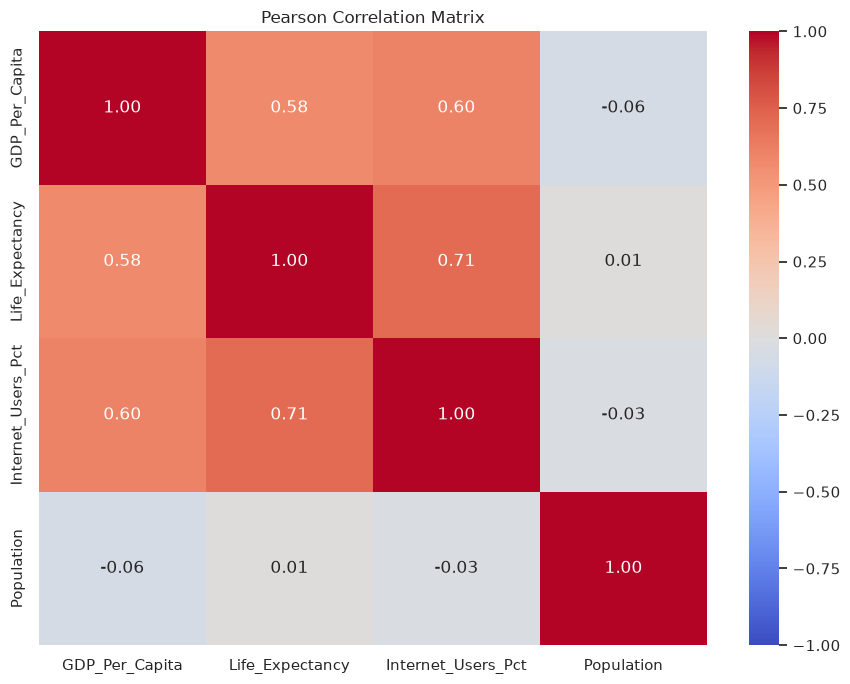

In [10]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()


### Correlation Interpretation

The strongest positive correlation is between Life Expectancy and Internet Users (r = 0.711).

GDP per capita is positively correlated with Life Expectancy (r = 0.577) and Internet Users (r = 0.604).

Population has very weak linear correlations with the other indicators in this dataset. Correlation describes association, not causation.


## 7. Interactive GDP per Capita Time Series

In [11]:
create_gdp_time_series(cleaned_df)


The interactive Plotly chart compares Germany and Algeria over time. Hovering displays values, while zoom and pan allow closer inspection.


## 8. Geographical Visualization: Life Expectancy

In [12]:
create_life_expectancy_map(cleaned_df)


The Folium choropleth displays life expectancy for the latest available year. The map uses the supplied GeoJSON boundaries. Some economies cannot appear because their geographic features are not available in the GeoJSON file.


## 9. Network Analysis: Regional Hierarchy

In [13]:
graph, latest_year = build_regional_graph(cleaned_df)

print("Graph nodes:", graph.number_of_nodes())
print("Graph edges:", graph.number_of_edges())

draw_regional_graph(graph, latest_year)
plt.show()


Graph nodes: 225
Graph edges: 224


/workspaces/DataVisualisation-TP4/src/network_analysis.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


### Discussion

NetworkX represents the hierarchy as a directed graph: the World node connects to regional nodes, and each regional node connects to its countries.

This graph models geographical organization, not direct economic relationships. Modeling trade, investment, or economic influence would require external datasets such as bilateral trade flows or foreign direct investment.


## 10. Limitations

- GDP per capita is expressed in current US dollars and is not adjusted for inflation.
- Missing GDP and Internet usage observations are retained rather than artificially imputed.
- The choropleth map is limited by GeoJSON country coverage.
- Pearson correlation measures linear association and does not establish causality.
- The analysis combines observations across multiple years; country-level and time-level effects may differ.


## 11. Conclusion

This practical work combines static and interactive visualizations to investigate global development indicators. Scatter, bubble, and density plots reveal different aspects of the GDP–life expectancy relationship. Correlation analysis identifies associations among development indicators, while Plotly, Folium, and NetworkX provide interactive, geographical, and hierarchical perspectives.
